# Metaverse Transactions: Preprocessing & Data Audit

**Goal:** turn the raw transaction log into a clean, leakage-aware, model-ready dataset for classifying
each transaction as **low / moderate / high risk**.

Every cleaning, dropping and feature decision below is **measured on the data first**, then implemented in
`preprocessing.py` (the same module the Streamlit app uses), so notebook, app and report always agree.

**What changed compared to the first version**

| Issue in v1 | Fix in v2 |
|---|---|
| `risk_score` fed to the models (it fully determines the label, 100% accuracy) | explicit *scenarios*: `full`, `no_score`, `behavioural` |
| `LabelEncoder` order (high=0, low=1, moderate=2) did not match the plotted class names | fixed order low=0 < moderate=1 < high=2 |
| `purchase_pattern` and `age_group` both encoded (they are the same column) | detected automatically (Cramér's V = 1.0), one kept |
| scaling / encoding learnt on the full data | everything fitted on the **train split only** inside a `ColumnTransformer` |
| random split, accuracy only | stratified or temporal split, class weights, macro-F1 |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from preprocessing import (load_raw, clean, engineer_features, encode_target, prepare_dataset,
                           PreprocessConfig, SCENARIOS, CLASS_NAMES, TARGET_ORDER, save_artifacts)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"low_risk": "#2a9d8f", "moderate_risk": "#e9c46a", "high_risk": "#e63946"}
raw = load_raw()
raw.head()

,timestamp,hour_of_day,sending_address,receiving_address,amount,transaction_type,location_region,ip_prefix,login_frequency,session_duration,purchase_pattern,age_group,risk_score,anomaly
0,2022-04-11 12:47:27,12,0x9d32d0bf2c00f41ce7ca01b66e174cc4dcb0c1da,0x39f82e1c09bc6d7baccc1e79e5621ff812f50572,796.949206,transfer,Europe,192.000,3,48,focused,established,18.75,low_risk
1,2022-06-14 19:12:46,19,0xd6e251c23cbf52dbd472f079147873e655d8096f,0x51e8fbe24f124e0e30a614e14401b9bbfed5384c,0.010000,purchase,South America,172.000,5,61,focused,established,25.00,low_risk
2,2022-01-18 16:26:59,16,0x2e0925b922fed01f6a85d213ae2718f54b8ca305,0x52c7911879f783d590af45bda0c0ef2b8536706f,778.197390,purchase,Asia,192.168,3,74,focused,established,31.25,low_risk
3,2022-06-15 09:20:04,9,0x93efefc25fcaf31d7695f28018d7a11ece55457f,0x8ac3b7bd531b3a833032f07d4e47c7af6ea7bace,300.838358,transfer,South America,172.000,8,111,high_value,veteran,36.75,low_risk
4,2022-02-18 14:35:30,14,0xad3b8de45d63f5cce28aef9a82cf30c397c6ceb9,0x6fdc047c2391615b3facd79b4588c7e9106e49f2,775.569344,sale,Africa,172.160,6,100,high_value,veteran,62.50,moderate_risk


## 1. Raw data overview

In [2]:
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
print("missing values :", int(raw.isna().sum().sum()))
print("duplicate rows :", int(raw.duplicated().sum()))
print("unique senders :", raw.sending_address.nunique(), "| receivers:", raw.receiving_address.nunique())
raw.describe().T.round(2)

78,600 rows x 14 columns
missing values : 0
duplicate rows : 0
unique senders : 1161 | receivers: 1166


,count,mean,std,min,25%,50%,75%,max
hour_of_day,78600.0,11.53,6.94,0.00,6.00,12.00,18.00,23.00
amount,78600.0,502.57,245.90,0.01,331.32,500.03,669.53,1557.15
ip_prefix,78600.0,147.64,69.39,10.00,172.00,172.16,192.00,192.17
login_frequency,78600.0,4.18,2.37,1.00,2.00,4.00,6.00,8.00
session_duration,78600.0,69.68,40.52,20.00,35.00,60.00,100.00,159.00
risk_score,78600.0,44.96,21.78,15.00,26.25,40.00,52.50,100.00


**Reading:** the file is already complete (no missing values, no duplicates), but the cleaning step is still
implemented and tested (out-of-range values, bad timestamps, unseen categories, dirty text) so the pipeline
also works on new or messier exports.

Only ~1,160 distinct addresses produce 78,600 transactions: addresses are **identifiers**, not features, and
would let a model memorise users. They are dropped.

## 2. Target: class balance

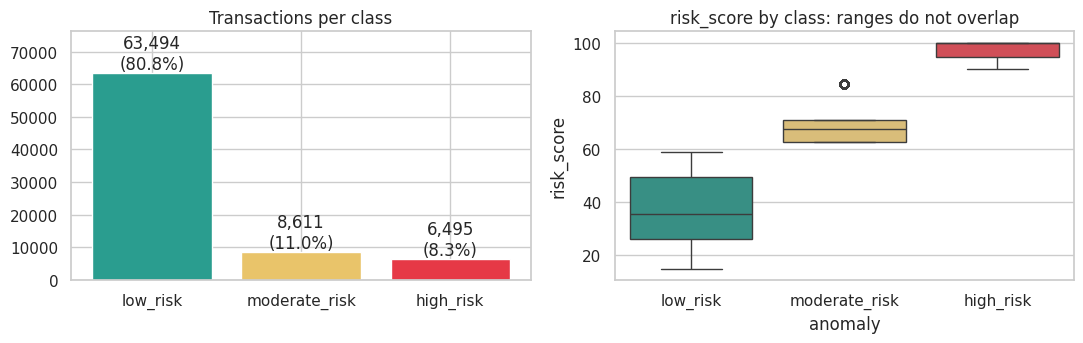

                min       max
anomaly                      
low_risk       15.0   59.0625
moderate_risk  62.5   84.3750
high_risk      90.0  100.0000


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cnt = raw.anomaly.value_counts().reindex(TARGET_ORDER)
ax[0].bar(cnt.index, cnt.values, color=[PALETTE[k] for k in cnt.index]); ax[0].set_title("Transactions per class")
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}\n({v/len(raw):.1%})", ha="center", va="bottom")
ax[0].set_ylim(0, cnt.max()*1.2)
sns.boxplot(data=raw, x="anomaly", y="risk_score", order=TARGET_ORDER, palette=PALETTE, ax=ax[1])
ax[1].set_title("risk_score by class: ranges do not overlap")
plt.tight_layout(); plt.show()
print(raw.groupby("anomaly").risk_score.agg(["min", "max"]).reindex(TARGET_ORDER))

**Reading:** the classes are imbalanced (81% / 11% / 8%), so **accuracy is misleading**: always predicting "low risk"
already scores 80.8%. We therefore use macro-F1 and balanced class weights.

The right plot is the key finding: `risk_score` ranges **never overlap** across classes (15-59 / 62.5-84 / 90-100).
The label is just a thresholding of `risk_score`, so using it as a feature is data leakage.

## 3. Exploratory analysis

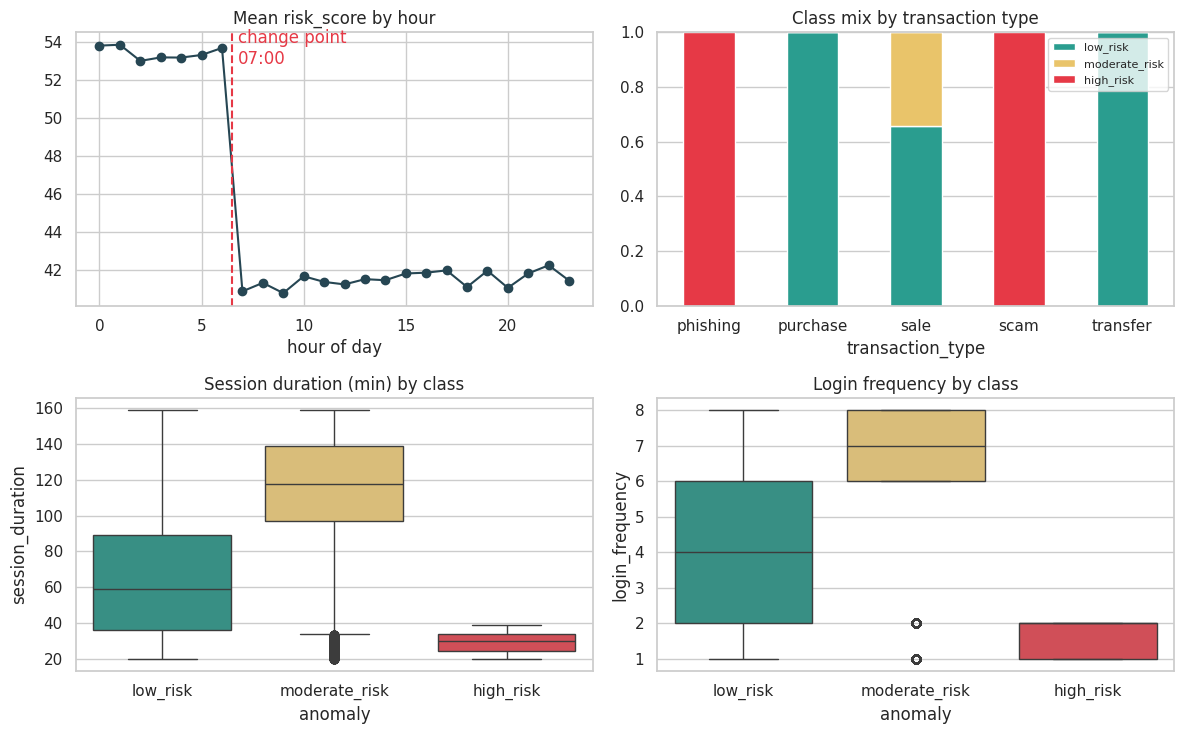

In [4]:
df, log = clean(raw)
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))

# (a) risk by hour -> reveals a change point
h = df.groupby("hour_of_day").risk_score.mean()
ax[0,0].plot(h.index, h.values, marker="o", color="#264653"); ax[0,0].axvline(6.5, color="#e63946", ls="--")
ax[0,0].text(6.8, h.max()-1, "change point\n07:00", color="#e63946")
ax[0,0].set_title("Mean risk_score by hour"); ax[0,0].set_xlabel("hour of day")

# (b) class mix by transaction type
mix = pd.crosstab(df.transaction_type, df.anomaly, normalize="index")[TARGET_ORDER]
mix.plot(kind="bar", stacked=True, color=[PALETTE[c] for c in mix.columns], ax=ax[0,1], rot=0)
ax[0,1].set_title("Class mix by transaction type"); ax[0,1].legend(fontsize=8)

# (c) behaviour
sns.boxplot(data=df, x="anomaly", y="session_duration", order=TARGET_ORDER, palette=PALETTE, ax=ax[1,0])
ax[1,0].set_title("Session duration (min) by class")
sns.boxplot(data=df, x="anomaly", y="login_frequency", order=TARGET_ORDER, palette=PALETTE, ax=ax[1,1])
ax[1,1].set_title("Login frequency by class")
plt.tight_layout(); plt.show()

**What the plots tell us**

* **Hour of day:** the average risk drops sharply at **07:00**. Night-time (0-6h) is a distinct regime, so an explicit
  `is_night` flag is engineered in addition to the cyclic `sin/cos(hour)` encoding (hour 23 and hour 0 are neighbours).
* **Transaction type:** `phishing` and `scam` are *always* high risk, `purchase` and `transfer` are *always* low risk,
  and only `sale` is mixed. This one column is nearly a label.
* **Behaviour:** moderate-risk users log in more and stay longer, high-risk users do the opposite. These are
  genuine behavioural signals, which is exactly what the `behavioural` scenario keeps.

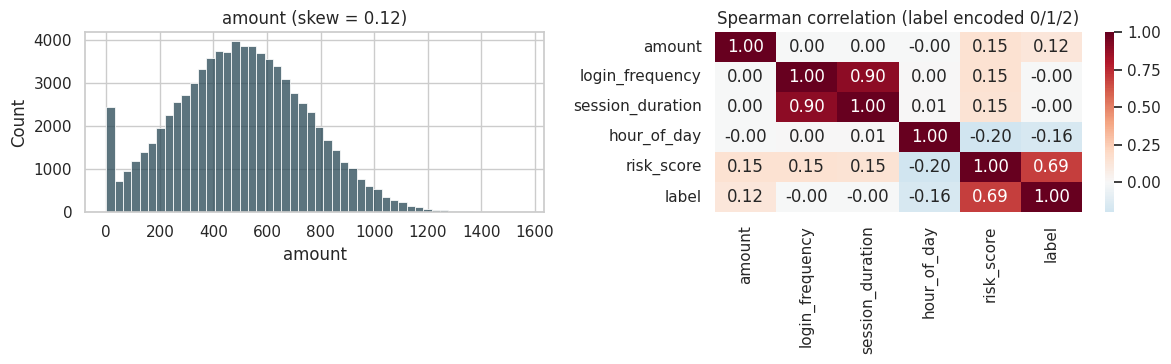

amount quantiles: {0.001: 0.0, 0.5: 500.0, 0.99: 1083.2, 0.999: 1281.6}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df.amount, bins=50, color="#264653", ax=ax[0]); ax[0].set_title(f"amount (skew = {df.amount.skew():.2f})")
num = df[["amount","login_frequency","session_duration","hour_of_day","risk_score"]].assign(label=encode_target(df.anomaly))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("Spearman correlation (label encoded 0/1/2)")
plt.tight_layout(); plt.show()
print("amount quantiles:", df.amount.quantile([.001, .5, .99, .999]).round(1).to_dict())

**Reading:** `amount` is almost symmetric (skew 0.12) so a log transform would add nothing; we only **winsorise** at the
0.1% / 99.9% quantiles (learnt on train) to neutralise rare extremes. `risk_score` is again the feature that is most
correlated with the label.

## 4. Audit: which columns should be kept?

### 4.1 Redundant categorical columns

In [6]:
print(pd.crosstab(df.age_group, df.purchase_pattern))

purchase_pattern  focused  high_value  random
age_group                                    
established         26033           0       0
new                     0           0   26145
veteran                 0       26422       0


`age_group` and `purchase_pattern` are the **same variable under two names** (veteran = high_value, new = random,
established = focused). Keeping both only duplicates information, so the audit detects pairs with Cramér's V >= 0.99
and drops one (`age_group` is kept because it has a natural order: new < established < veteran).

### 4.2 Columns with no signal

In [7]:
data = prepare_dataset(raw=raw, config=PreprocessConfig(scenario="behavioural"))
assoc = pd.DataFrame(data.audit["categorical_analysis"]["association_with_target"]).T
assoc

,cramers_v,p_value,is_noise
transaction_type,0.7921,0.0,False
location_region,0.0075,0.3589,True
ip_prefix,0.0067,0.5332,True
purchase_pattern,0.434,0.0,False
age_group,0.434,0.0,False


`location_region` (V = 0.007) and `ip_prefix` (V = 0.007) have **no statistically meaningful link** with the risk level
(p > 0.3), so they are dropped automatically. Their class mix is identical in every region and every IP block.

### 4.3 Leakage scan: how well does *one* feature predict the label?

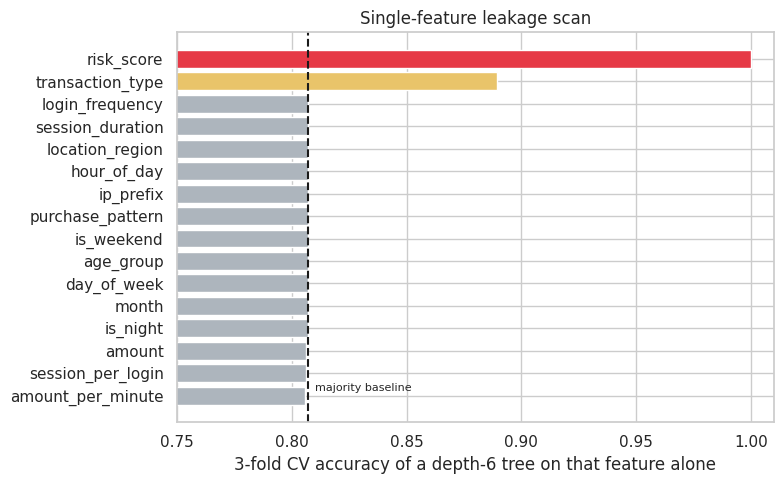

In [8]:
scan = pd.DataFrame(data.audit["leakage_scan"])
fig, ax = plt.subplots(figsize=(8, 5))
colors = scan.verdict.map({"LEAK": "#e63946", "strong": "#e9c46a", "weak": "#adb5bd"})
ax.barh(scan.feature[::-1], scan.single_feature_accuracy[::-1], color=colors[::-1])
ax.axvline(scan.majority_baseline.iloc[0], color="k", ls="--"); ax.text(scan.majority_baseline.iloc[0]+.003, 0.2, "majority baseline", fontsize=8)
ax.set_xlim(0.75, 1.01); ax.set_xlabel("3-fold CV accuracy of a depth-6 tree on that feature alone")
ax.set_title("Single-feature leakage scan"); plt.tight_layout(); plt.show()

`risk_score` alone reaches **100%** (leak). `transaction_type` alone reaches **88.9%**. All other single features sit at the
baseline, but that does **not** mean they are useless: they work in *combination*, which the next probe shows.

### 4.4 Rule probe: is the label a simple rule?

In [9]:
print(data.audit["rule_probe_without_risk_score"])

|--- transaction_type_scam <= 0.50
|   |--- transaction_type_phishing <= 0.50
|   |   |--- transaction_type_sale <= 0.50
|   |   |   |--- class: 0
|   |   |--- transaction_type_sale >  0.50
|   |   |   |--- hour_of_day <= 6.50
|   |   |   |   |--- class: 1
|   |   |   |--- hour_of_day >  6.50
|   |   |   |   |--- class: 0
|   |--- transaction_type_phishing >  0.50
|   |   |--- class: 2
|--- transaction_type_scam >  0.50
|   |--- class: 2



Even **without** `risk_score`, a tree of depth 4 approximately describes the label: *scam/phishing -> high; sale at night -> moderate;
everything else -> low*. The dataset is **synthetic and rule-generated**, so any model with `transaction_type` will
approach 100%. This is why the project exposes three scenarios instead of pretending one setup is "the" benchmark.

### 4.5 Information content of numeric features

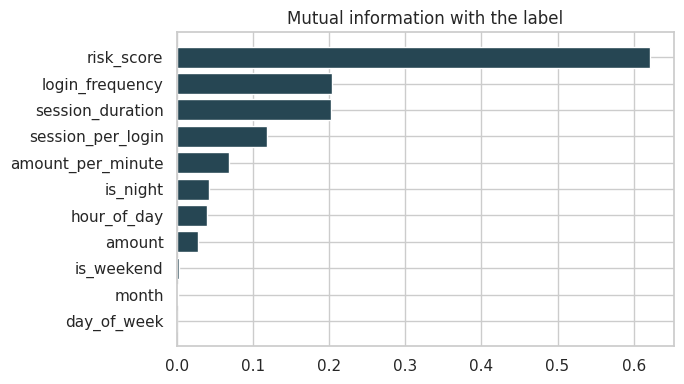

In [10]:
mi = pd.DataFrame(data.audit["mutual_information"])
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh(mi.feature[::-1], mi.mutual_information[::-1], color="#264653")
ax.set_title("Mutual information with the label"); plt.tight_layout(); plt.show()

* `login_frequency` and `session_duration` carry the most information among behavioural features.
* The engineered ratios **`session_per_login`** and **`amount_per_minute`** have more information than `amount` itself.
* `day_of_week`, `month` and `is_weekend` are ~0, so they are **excluded by default** (`calendar_features=False`).

## 5. Feature scenarios

| Scenario | Removes | Purpose |
|---|---|---|
| `full` | nothing | demonstrates the leakage (do not use for conclusions) |
| `no_score` | `risk_score` | realistic baseline, but still near-deterministic via `transaction_type` |
| `behavioural` | `risk_score`, `transaction_type` | the genuinely hard problem, where models differ |

In [11]:
rows = []
for sc in SCENARIOS:
    for sp in ["stratified", "temporal"]:
        d = prepare_dataset(raw=raw, config=PreprocessConfig(scenario=sc, split=sp))
        for name, m in {"Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=0),
                        "Logistic Regression": LogisticRegression(max_iter=500, class_weight="balanced")}.items():
            m.fit(d.X_train, d.y_train); p = m.predict(d.X_test)
            rows.append(dict(scenario=sc, split=sp, model=name, n_features=len(d.feature_names),
                             accuracy=round((p == d.y_test).mean(), 3), macro_F1=round(f1_score(d.y_test, p, average="macro"), 3)))
res = pd.DataFrame(rows); res.pivot_table(index=["scenario", "split"], columns="model", values=["accuracy", "macro_F1"])

accuracy                          macro_F1  \
model                  Decision Tree Logistic Regression Decision Tree   
scenario    split                                                        
behavioural stratified         0.710               0.664         0.663   
            temporal           0.705               0.663         0.657   
full        stratified         1.000               1.000         1.000   
            temporal           1.000               1.000         1.000   
no_score    stratified         1.000               0.987         1.000   
            temporal           1.000               0.990         1.000   

                                            
model                  Logistic Regression  
scenario    split                           
behavioural stratified               0.609  
            temporal                 0.607  
full        stratified               1.000  
            temporal                 1.000  
no_score    stratified               0.979  
            temporal                 0.983

**Reading:** with `full` or `no_score` even a small decision tree is perfect; only in the `behavioural` scenario do
accuracy (~0.71) and macro-F1 (~0.61-0.66) leave room for model comparison. The **temporal split** (train on the
past, test on the future) gives the same picture, so the result is not a random-split artefact.

## 6. The preprocessing pipeline in action

In [12]:
cfg = PreprocessConfig(scenario="behavioural", split="stratified", scaler="standard")
data = prepare_dataset(raw=raw, config=cfg)
for i, s in enumerate(data.steps, 1): print(f"{i}. {s['step']}\n   {s['detail']}\n")

1. Load & validate
   78,600 rows x 14 columns, schema OK

2. Clean
   78,600 -> 78,600 rows | duplicates removed: 0 | out-of-range values -> NaN: 0 | hour/timestamp mismatches fixed: 0 | sorted by timestamp

3. Encode target
   low_risk=0 < moderate_risk=1 < high_risk=2 (fixed order, class names now match the encoding)

4. Engineer features
   time: is_night, hour_sin, hour_cos; night=0-6h (weekday/month/weekend computed for the audit but excluded: mutual information ~ 0); interactions: amount_per_minute, session_per_login

5. Audit
   leakage scan flagged ['risk_score']; redundant pairs: [('purchase_pattern', 'age_group')]; noise categoricals: ['location_region', 'ip_prefix']

6. Select features
   dropped: risk_score [scenario 'behavioural']; transaction_type [scenario 'behavioural']; purchase_pattern [duplicate of 'age_group' (Cramér's V=1.0)]; location_region [no association with target (V=0.0075, p=0.3589)]; ip_prefix [no association with target (V=0.0067, p=0.5332)]; identifiers

In [13]:
print("Dropped columns:"); [print(f"  - {k:18s} {v}") for k, v in data.dropped.items()]
print("\nFeature groups:"); [print(f"  {k:8s} {v}") for k, v in data.feature_groups.items()]
print("\nFinal matrix:", data.X_train.shape, "(train) |", data.X_test.shape, "(test)")
data.X_train.head()

Dropped columns:
  - sending_address    identifier
  - receiving_address  identifier
  - timestamp          replaced by engineered time features
  - risk_score         scenario 'behavioural'
  - transaction_type   scenario 'behavioural'
  - purchase_pattern   duplicate of 'age_group' (Cramér's V=1.0)
  - location_region    no association with target (V=0.0075, p=0.3589)
  - ip_prefix          no association with target (V=0.0067, p=0.5332)

Feature groups:
  numeric  ['amount', 'login_frequency', 'session_duration', 'hour_of_day', 'amount_per_minute', 'session_per_login', 'hour_sin', 'hour_cos']
  binary   ['is_night']
  nominal  []
  ordinal  ['age_group']

Final matrix: (55020, 10) (train) | (23580, 10) (test)


,amount,login_frequency,session_duration,hour_of_day,amount_per_minute,session_per_login,hour_sin,hour_cos,is_night,age_group
51879,-0.407074,1.616954,0.773644,0.064728,-0.751838,-0.554525,0.006052,-1.413647,0.0,1.0
75687,-1.433282,-1.339992,-1.149657,1.074623,-0.464285,-0.477074,-1.361450,0.364708,0.0,0.0
56862,0.503749,-1.339992,-1.124999,0.641811,1.860631,-0.337663,-1.220017,-0.707288,0.0,0.0
6420,-1.669978,-0.072730,0.033913,0.208999,-1.081632,0.275746,-0.360369,-1.365510,0.0,0.5
19582,-0.636914,-0.917572,-0.952395,0.786081,0.098415,-0.802367,-1.361450,-0.366568,0.0,0.0


### Before / after

In [14]:
raw_view = data.clean_df[["hour_of_day","amount","login_frequency","session_duration","age_group","is_night"]].head(5)
display(raw_view.style.set_caption("Cleaned + engineered (before encoding / scaling)"))
display(data.X_train.head(5).round(3).style.set_caption("Model-ready (after imputation, clipping, scaling, encoding)"))

,hour_of_day,amount,login_frequency,session_duration,age_group,is_night
0,0.000000,592.024530,6.000000,84.000000,veteran,1.000000
1,0.000000,755.500717,3.000000,70.000000,established,1.000000
2,0.000000,247.716361,5.000000,54.000000,established,1.000000
3,0.000000,422.789709,4.000000,62.000000,established,1.000000
4,0.000000,353.949174,7.000000,94.000000,veteran,1.000000


,amount,login_frequency,session_duration,hour_of_day,amount_per_minute,session_per_login,hour_sin,hour_cos,is_night,age_group
51879,-0.407000,1.617000,0.774000,0.065000,-0.752000,-0.555000,0.006000,-1.414000,0.000000,1.000000
75687,-1.433000,-1.340000,-1.150000,1.075000,-0.464000,-0.477000,-1.361000,0.365000,0.000000,0.000000
56862,0.504000,-1.340000,-1.125000,0.642000,1.861000,-0.338000,-1.220000,-0.707000,0.000000,0.000000
6420,-1.670000,-0.073000,0.034000,0.209000,-1.082000,0.276000,-0.360000,-1.366000,0.000000,0.500000
19582,-0.637000,-0.918000,-0.952000,0.786000,0.098000,-0.802000,-1.361000,-0.367000,0.000000,0.000000


### Sanity checks

In [15]:
assert not data.X_train.isna().any().any() and not data.X_test.isna().any().any(), "NaN left"
assert list(data.X_train.columns) == list(data.X_test.columns), "column mismatch"
assert "risk_score" not in data.feature_names and "transaction_type" not in " ".join(data.feature_names)
scaler = data.preprocessor.named_transformers_["num"].named_steps["scale"]
assert scaler.n_samples_seen_ == len(data.X_train), "scaler saw more than the train split"
sh_tr = data.y_train.value_counts(normalize=True).sort_index(); sh_te = data.y_test.value_counts(normalize=True).sort_index()
print(pd.DataFrame({"train": sh_tr.round(4).values, "test": sh_te.round(4).values}, index=CLASS_NAMES))
print("\nAll checks passed: no NaN, same columns, no leaking feature, scaler fitted on train only, same class mix in both splits.")

                train    test
low risk       0.8078  0.8078
moderate risk  0.1096  0.1095
high risk      0.0826  0.0827

All checks passed: no NaN, same columns, no leaking feature, scaler fitted on train only, same class mix in both splits.


### Saving artefacts for the app

In [16]:
out = save_artifacts(data, "artifacts"); print("saved ->", out.resolve()); print(sorted(p.name for p in out.iterdir()))

saved -> /home/claude/metaverse/artifacts
['audit.json', 'preprocessing_report.md', 'preprocessor.joblib', 'test_processed.csv', 'train_processed.csv']


## 7. Summary of decisions

1. **Dropped identifiers** (`sending_address`, `receiving_address`) to prevent memorising users.
2. **Dropped `purchase_pattern`** (duplicate of `age_group`), **`location_region`** and **`ip_prefix`** (no association with the target).
3. **Removed `risk_score`** (target leakage) and offered **`transaction_type`**-free scenario as the realistic hard case.
4. **Fixed target order** (low < moderate < high) so labels and plots always agree.
5. **Engineered** `is_night`, `sin/cos(hour)`, `session_per_login`, `amount_per_minute`; **excluded** calendar features (no signal) and
   sender history (no gain, and would re-introduce user-level leakage).
6. **Everything learnable is fitted on the train split only** (median imputation, 0.1-99.9% clipping, scaling, one-hot, ordinal).
7. **Imbalance handled** with balanced class weights; evaluation should use **macro-F1** (and PR-AUC), not accuracy alone.
8. **Stratified or temporal split** selectable; `MinMaxScaler` option keeps features non-negative for Naive Bayes.

Next step: `app.py` consumes `prepare_dataset()` directly.